Load data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats import norm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

from pathlib import Path
from google.colab import files

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

print("Upload hillstrom_clean.csv")
uploaded = files.upload()

df = pd.read_csv('hillstrom_clean.csv')
print(f"Loaded: {len(df):,} rows × {df.shape[1]} columns")


Upload hillstrom_clean.csv


Saving hillstrom_clean.csv to hillstrom_clean.csv
Loaded: 64,000 rows × 17 columns


 Define groups and helper functions

In [4]:
control = df[df['segment'] == 'No E-Mail']
mens    = df[df['segment'] == 'Mens E-Mail']
womens  = df[df['segment'] == 'Womens E-Mail']

print(f"Control      : {len(control):,} customers")
print(f"Mens email   : {len(mens):,} customers")
print(f"Womens email : {len(womens):,} customers")
print()

# ── Helper: two-proportion z-test ─────────────────────────────────────────────
def proportion_ztest(n_treat, x_treat, n_ctrl, x_ctrl):
    """
    Tests H0: p_treatment = p_control
    Returns: z-statistic, p-value, absolute lift, relative lift
    """
    p_treat = x_treat / n_treat
    p_ctrl  = x_ctrl  / n_ctrl
    p_pool  = (x_treat + x_ctrl) / (n_treat + n_ctrl)
    se      = np.sqrt(p_pool * (1 - p_pool) * (1/n_treat + 1/n_ctrl))
    z       = (p_treat - p_ctrl) / se
    p_val   = 2 * (1 - norm.cdf(abs(z)))
    abs_lift = p_treat - p_ctrl
    rel_lift = abs_lift / p_ctrl
    return z, p_val, abs_lift, rel_lift

# ── Helper: bootstrap confidence interval ────────────────────────────────────
def bootstrap_ci(treat_vals, ctrl_vals, n_boot=5000, ci=0.95, seed=42):
    """
    Non-parametric bootstrap CI around the difference in means.
    Does not assume normality — robust to skewed distributions like spend.
    """
    np.random.seed(seed)
    diffs = [
        np.random.choice(treat_vals, len(treat_vals), replace=True).mean()
      - np.random.choice(ctrl_vals,  len(ctrl_vals),  replace=True).mean()
        for _ in range(n_boot)
    ]
    alpha = (1 - ci) / 2
    return np.percentile(diffs, [alpha*100, (1-alpha)*100]), np.array(diffs)

# ── Helper: Cohen's h (effect size for proportions) ──────────────────────────
def cohens_h(p1, p2):
    return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))

print("Helper functions defined.")
print()
print("Statistical framework:")
print("  H0 (null hypothesis)     : The email has NO effect on the outcome.")
print("  H1 (alternative)         : The email DOES change the outcome.")
print("  Significance level α     : 0.05 (5% false positive rate we accept)")
print("  Reject H0 when           : p-value < 0.05")


Control      : 21,306 customers
Mens email   : 21,307 customers
Womens email : 21,387 customers

Helper functions defined.

Statistical framework:
  H0 (null hypothesis)     : The email has NO effect on the outcome.
  H1 (alternative)         : The email DOES change the outcome.
  Significance level α     : 0.05 (5% false positive rate we accept)
  Reject H0 when           : p-value < 0.05


Test 1: Visit rate (binary outcome)

In [5]:
outcomes = {
    'Visit Rate'      : 'visit',
    'Conversion Rate' : 'conversion',
}

print("TWO-PROPORTION Z-TEST")
print("Testing whether email groups have significantly higher rates than control.\n")

results = []
for label, col in outcomes.items():
    for name, grp in [('Mens Email', mens), ('Womens Email', womens)]:
        n_t = len(grp);       x_t = grp[col].sum()
        n_c = len(control);   x_c = control[col].sum()
        z, p, abs_lift, rel_lift = proportion_ztest(n_t, x_t, n_c, x_c)
        sig = "✓ SIGNIFICANT" if p < 0.05 else "✗ NOT significant"
        results.append({
            'Outcome': label, 'Campaign': name,
            'Control Rate': x_c/n_c, 'Treatment Rate': x_t/n_t,
            'Absolute Lift': abs_lift, 'Relative Lift': rel_lift,
            'Z-stat': z, 'P-value': p, 'Result': sig
        })
        print(f"{label} — {name}")
        print(f"  Control rate    : {x_c/n_c*100:.2f}%")
        print(f"  Treatment rate  : {x_t/n_t*100:.2f}%")
        print(f"  Absolute lift   : {abs_lift*100:.2f} percentage points")
        print(f"  Relative lift   : {rel_lift*100:.1f}%")
        print(f"  Z-statistic     : {z:.4f}")
        print(f"  P-value         : {p:.6f}  → {sig}")
        print()

binary_results = pd.DataFrame(results)


TWO-PROPORTION Z-TEST
Testing whether email groups have significantly higher rates than control.

Visit Rate — Mens Email
  Control rate    : 10.62%
  Treatment rate  : 18.28%
  Absolute lift   : 7.66 percentage points
  Relative lift   : 72.1%
  Z-statistic     : 22.4860
  P-value         : 0.000000  → ✓ SIGNIFICANT

Visit Rate — Womens Email
  Control rate    : 10.62%
  Treatment rate  : 15.14%
  Absolute lift   : 4.52 percentage points
  Relative lift   : 42.6%
  Z-statistic     : 13.9492
  P-value         : 0.000000  → ✓ SIGNIFICANT

Conversion Rate — Mens Email
  Control rate    : 0.57%
  Treatment rate  : 1.25%
  Absolute lift   : 0.68 percentage points
  Relative lift   : 118.8%
  Z-statistic     : 7.3851
  P-value         : 0.000000  → ✓ SIGNIFICANT

Conversion Rate — Womens Email
  Control rate    : 0.57%
  Treatment rate  : 0.88%
  Absolute lift   : 0.31 percentage points
  Relative lift   : 54.3%
  Z-statistic     : 3.7796
  P-value         : 0.000157  → ✓ SIGNIFICANT



Test 2: Average spend (continuous outcome)

In [6]:
print("TWO-SAMPLE T-TEST + MANN-WHITNEY U TEST")
print("Testing whether email groups spent significantly more than control.\n")
print("Note: spend is heavily right-skewed (most customers spend £0).")
print("We run both parametric (t-test) and non-parametric (Mann-Whitney) tests.\n")

spend_results = []
for name, grp in [('Mens Email', mens), ('Womens Email', womens)]:
    t_stat, p_ttest = stats.ttest_ind(grp['spend'], control['spend'])
    u_stat, p_mwu   = stats.mannwhitneyu(grp['spend'], control['spend'], alternative='two-sided')

    abs_lift = grp['spend'].mean() - control['spend'].mean()
    rel_lift = abs_lift / (control['spend'].mean() + 1e-9)

    # Cohen's d (effect size for continuous)
    pooled_std = np.sqrt((grp['spend'].std()**2 + control['spend'].std()**2) / 2)
    cohens_d   = abs_lift / pooled_std

    ci_bounds, _ = bootstrap_ci(grp['spend'].values, control['spend'].values)

    print(f"Average Spend — {name}")
    print(f"  Control mean     : £{control['spend'].mean():.4f}")
    print(f"  Treatment mean   : £{grp['spend'].mean():.4f}")
    print(f"  Absolute lift    : £{abs_lift:.4f}")
    print(f"  Relative lift    : {rel_lift*100:.1f}%")
    print(f"  95% bootstrap CI : [£{ci_bounds[0]:.4f}, £{ci_bounds[1]:.4f}]")
    print(f"  Cohen's d        : {cohens_d:.4f}  (small<0.2, medium<0.5, large>0.8)")
    print(f"  T-test p-value   : {p_ttest:.6f}  → {'✓ SIGNIFICANT' if p_ttest < 0.05 else '✗ NOT significant'}")
    print(f"  Mann-Whitney p   : {p_mwu:.6f}  → {'✓ SIGNIFICANT' if p_mwu < 0.05 else '✗ NOT significant'}")
    print()

    spend_results.append({
        'Campaign': name, 'Abs Lift (£)': abs_lift,
        'CI Lower': ci_bounds[0], 'CI Upper': ci_bounds[1],
        "Cohen's d": cohens_d, 'T-test p': p_ttest, 'MWU p': p_mwu
    })

spend_df = pd.DataFrame(spend_results)


TWO-SAMPLE T-TEST + MANN-WHITNEY U TEST
Testing whether email groups spent significantly more than control.

Note: spend is heavily right-skewed (most customers spend £0).
We run both parametric (t-test) and non-parametric (Mann-Whitney) tests.

Average Spend — Mens Email
  Control mean     : £0.6528
  Treatment mean   : £1.4226
  Absolute lift    : £0.7698
  Relative lift    : 117.9%
  95% bootstrap CI : [£0.5007, £1.0532]
  Cohen's d        : 0.0514  (small<0.2, medium<0.5, large>0.8)
  T-test p-value   : 0.000000  → ✓ SIGNIFICANT
  Mann-Whitney p   : 0.000000  → ✓ SIGNIFICANT

Average Spend — Womens Email
  Control mean     : £0.6528
  Treatment mean   : £1.0772
  Absolute lift    : £0.4244
  Relative lift    : 65.0%
  95% bootstrap CI : [£0.1799, £0.6952]
  Cohen's d        : 0.0315  (small<0.2, medium<0.5, large>0.8)
  T-test p-value   : 0.001136  → ✓ SIGNIFICANT
  Mann-Whitney p   : 0.000155  → ✓ SIGNIFICANT



Confidence interval visualisation

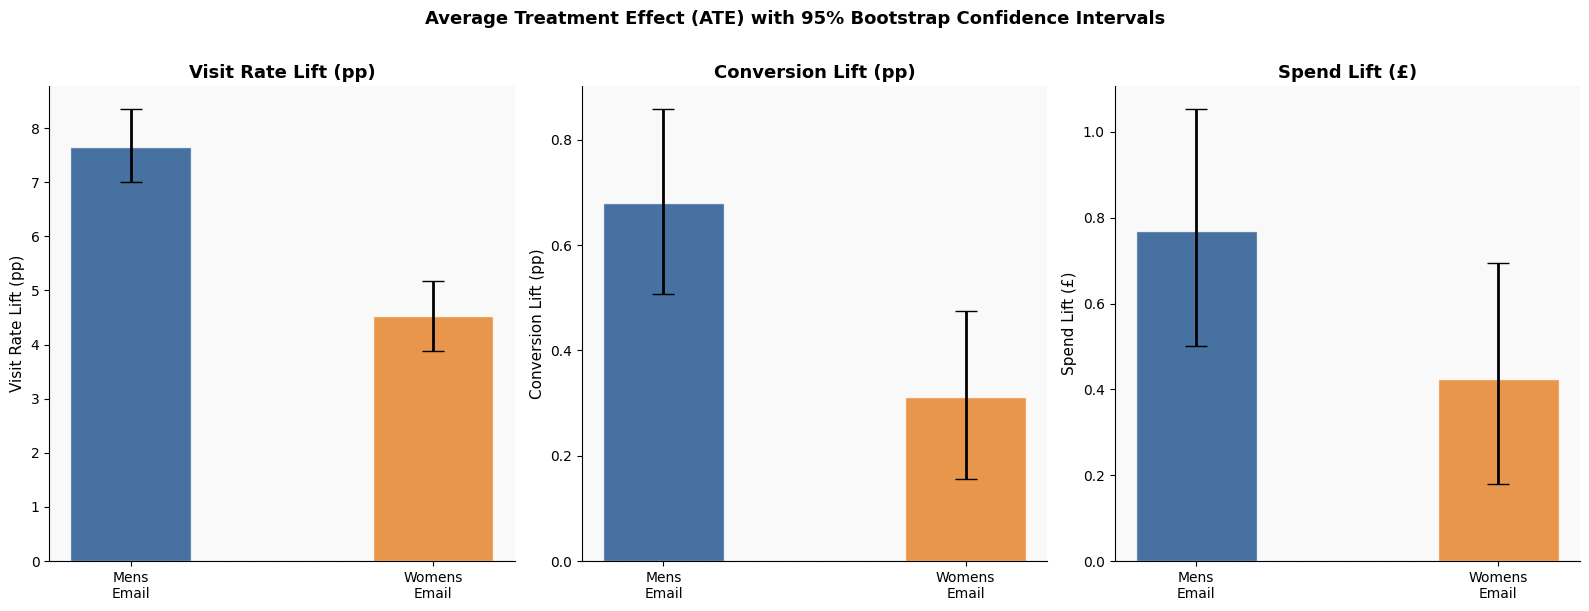

How to read this chart:
- Bar height = the Average Treatment Effect (ATE)
- Error bars = 95% bootstrap confidence interval
- If the CI does NOT cross zero, the effect is statistically significant.
- A narrow CI means high precision — more data → more certainty.


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Average Treatment Effect (ATE) with 95% Bootstrap Confidence Intervals',
             fontsize=13, fontweight='bold', y=1.01)

outcomes_ci = [
    ('visit',      'Visit Rate Lift (pp)',  100),
    ('conversion', 'Conversion Lift (pp)',  100),
    ('spend',      'Spend Lift (£)',         1),
]

for ax, (col, ylabel, scale) in zip(axes, outcomes_ci):
    lifts, ci_lows, ci_highs = [], [], []
    labels = []
    for name, grp in [('Mens\nEmail', mens), ('Womens\nEmail', womens)]:
        ci_bounds, _ = bootstrap_ci(grp[col].values, control[col].values)
        lift = (grp[col].mean() - control[col].mean()) * scale
        ci_l = ci_bounds[0] * scale
        ci_h = ci_bounds[1] * scale
        lifts.append(lift)
        ci_lows.append(lift - ci_l)
        ci_highs.append(ci_h - lift)
        labels.append(name)

    colors = [BLUE, ORANGE]
    bars = ax.bar(labels, lifts, color=colors, alpha=0.8, edgecolor='white', width=0.4)
    ax.errorbar(labels, lifts,
                yerr=[ci_lows, ci_highs],
                fmt='none', color='black', capsize=8, linewidth=2)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.set_title(ylabel, fontweight='bold')
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.savefig(FIGURES / '05_ate_confidence_intervals.png', dpi=150, bbox_inches='tight')
plt.show()

print("How to read this chart:")
print("- Bar height = the Average Treatment Effect (ATE)")
print("- Error bars = 95% bootstrap confidence interval")
print("- If the CI does NOT cross zero, the effect is statistically significant.")
print("- A narrow CI means high precision — more data → more certainty.")


Bootstrap distribution plots

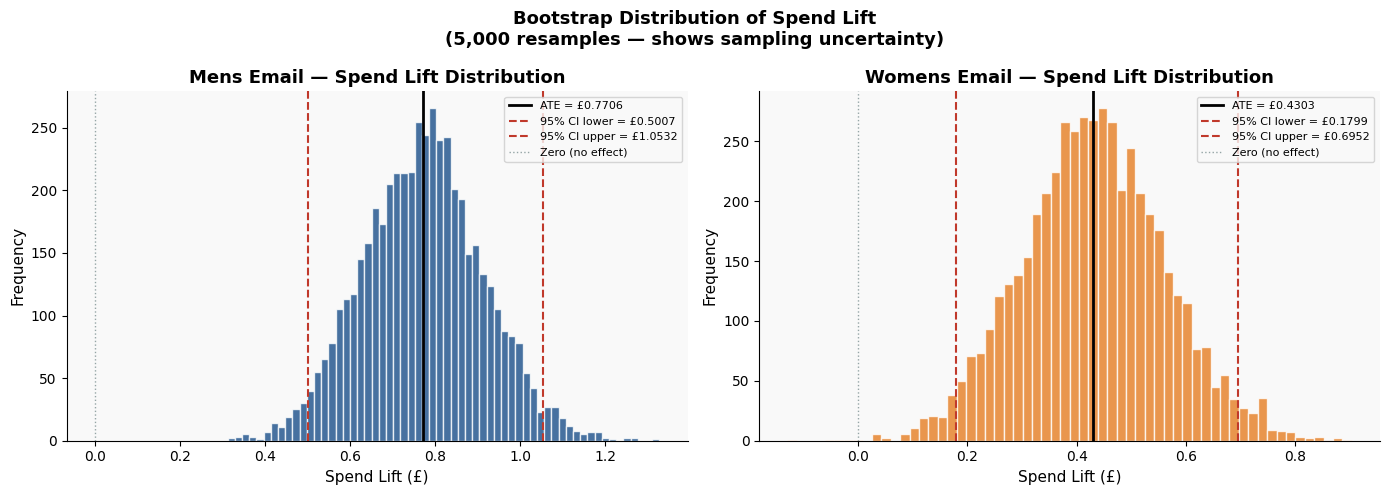

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Bootstrap Distribution of Spend Lift\n(5,000 resamples — shows sampling uncertainty)',
             fontsize=13, fontweight='bold')

for ax, (name, grp, color) in zip(axes, [('Mens Email', mens, BLUE), ('Womens Email', womens, ORANGE)]):
    _, boot_diffs = bootstrap_ci(grp['spend'].values, control['spend'].values)
    ci_lo, ci_hi = np.percentile(boot_diffs, [2.5, 97.5])

    ax.hist(boot_diffs, bins=60, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(boot_diffs.mean(), color='black', lw=2,    label=f'ATE = £{boot_diffs.mean():.4f}')
    ax.axvline(ci_lo,             color=RED,    lw=1.5, linestyle='--', label=f'95% CI lower = £{ci_lo:.4f}')
    ax.axvline(ci_hi,             color=RED,    lw=1.5, linestyle='--', label=f'95% CI upper = £{ci_hi:.4f}')
    ax.axvline(0,                 color=GREY,   lw=1,   linestyle=':',  label='Zero (no effect)')
    ax.set_title(f'{name} — Spend Lift Distribution', fontweight='bold')
    ax.set_xlabel('Spend Lift (£)')
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES / '06_bootstrap_distributions.png', dpi=150, bbox_inches='tight')
plt.show()


Power analysis

In [9]:
print("POWER ANALYSIS")
print("Given our sample sizes, what is the smallest effect we could reliably detect?\n")

from scipy.stats import norm as sp_norm

def minimum_detectable_effect(n1, n2, alpha=0.05, power=0.80):
    """MDE for a two-proportion test."""
    z_alpha = sp_norm.ppf(1 - alpha/2)
    z_beta  = sp_norm.ppf(power)
    # Approximate formula — assumes equal proportions near 0.1 (visit rate)
    p_avg = 0.10
    se    = np.sqrt(2 * p_avg * (1 - p_avg) * (1/n1 + 1/n2))
    mde   = (z_alpha + z_beta) * se
    return mde

n_ctrl  = len(control)
n_mens  = len(mens)
n_wom   = len(womens)

mde_mens  = minimum_detectable_effect(n_mens, n_ctrl)
mde_wom   = minimum_detectable_effect(n_wom,  n_ctrl)

print(f"Sample sizes: Control={n_ctrl:,}  Mens={n_mens:,}  Womens={n_wom:,}")
print(f"Significance level α = 0.05  |  Power = 80%")
print()
print(f"Minimum Detectable Effect (visit rate):")
print(f"  Mens email   : {mde_mens*100:.2f} percentage points")
print(f"  Womens email : {mde_wom*100:.2f} percentage points")
print()
print("Interpretation: With these sample sizes, we can reliably detect")
print(f"a lift as small as {mde_mens*100:.2f}pp. Any real effect smaller than")
print("this would be missed — but any real effect larger would be detected.")
print()
print("Our observed lifts are:")
for name, grp in [('Mens email', mens), ('Womens email', womens)]:
    obs = (grp['visit'].mean() - control['visit'].mean()) * 100
    print(f"  {name}: {obs:.2f}pp  → {'detectable ✓' if abs(obs) > mde_mens*100 else 'below MDE ✗'}")


POWER ANALYSIS
Given our sample sizes, what is the smallest effect we could reliably detect?

Sample sizes: Control=21,306  Mens=21,307  Womens=21,387
Significance level α = 0.05  |  Power = 80%

Minimum Detectable Effect (visit rate):
  Mens email   : 1.15 percentage points
  Womens email : 1.15 percentage points

Interpretation: With these sample sizes, we can reliably detect
a lift as small as 1.15pp. Any real effect smaller than
this would be missed — but any real effect larger would be detected.

Our observed lifts are:
  Mens email: 7.66pp  → detectable ✓
  Womens email: 4.52pp  → detectable ✓


 Multiple testing correction

In [11]:
print("MULTIPLE TESTING CORRECTION (Bonferroni)")
print()
print("We tested 6 hypotheses (3 outcomes × 2 treatment groups).")
print("At α=0.05 each, the chance of at least one false positive is:")
print(f"  1 - (1-0.05)^6 = {(1 - 0.95**6)*100:.1f}%")
print()
print("Bonferroni correction: adjust α to 0.05 / 6 = {:.4f}".format(0.05/6))
print()

bonferroni_alpha = 0.05 / 6

all_tests = [
    ('Visit Rate',       'Mens Email',   proportion_ztest(len(mens),   mens['visit'].sum(),      len(control), control['visit'].sum())[1]),
    ('Visit Rate',       'Womens Email', proportion_ztest(len(womens), womens['visit'].sum(),    len(control), control['visit'].sum())[1]),
    ('Conversion Rate',  'Mens Email',   proportion_ztest(len(mens),   mens['conversion'].sum(), len(control), control['conversion'].sum())[1]),
    ('Conversion Rate',  'Womens Email', proportion_ztest(len(womens), womens['conversion'].sum(),len(control),control['conversion'].sum())[1]),
    ('Spend',            'Mens Email',   stats.ttest_ind(mens['spend'], control['spend'])[1]),
    ('Spend',            'Womens Email', stats.ttest_ind(womens['spend'], control['spend'])[1]),
]

print(f"{'Outcome':<20} {'Campaign':<15} {'P-value':<12} {'α=0.05':<15} {'Bonferroni α'}")
print("-" * 75)
for outcome, campaign, p in all_tests:
    sig_naive       = "✓" if p < 0.05        else "✗"
    sig_bonferroni  = "✓" if p < bonferroni_alpha else "✗"
    print(f"{outcome:<20} {campaign:<15} {p:<12.6f} {sig_naive:<15} {sig_bonferroni}")

print()


MULTIPLE TESTING CORRECTION (Bonferroni)

We tested 6 hypotheses (3 outcomes × 2 treatment groups).
At α=0.05 each, the chance of at least one false positive is:
  1 - (1-0.05)^6 = 26.5%

Bonferroni correction: adjust α to 0.05 / 6 = 0.0083

Outcome              Campaign        P-value      α=0.05          Bonferroni α
---------------------------------------------------------------------------
Visit Rate           Mens Email      0.000000     ✓               ✓
Visit Rate           Womens Email    0.000000     ✓               ✓
Conversion Rate      Mens Email      0.000000     ✓               ✓
Conversion Rate      Womens Email    0.000157     ✓               ✓
Spend                Mens Email      0.000000     ✓               ✓
Spend                Womens Email    0.001136     ✓               ✓



Incremental revenue calculation

In [12]:
print("INCREMENTAL REVENUE CALCULATION")
print("How much revenue did the campaign generate that would NOT have happened otherwise?\n")

for name, grp in [('Mens Email', mens), ('Womens Email', womens)]:
    control_spend_mean = control['spend'].mean()
    treat_spend_mean   = grp['spend'].mean()
    ate_spend          = treat_spend_mean - control_spend_mean
    incremental_rev    = ate_spend * len(grp)
    ci, _              = bootstrap_ci(grp['spend'].values, control['spend'].values)
    ci_rev_lo          = ci[0] * len(grp)
    ci_rev_hi          = ci[1] * len(grp)

    print(f"{name}")
    print(f"  Customers treated         : {len(grp):,}")
    print(f"  ATE (spend per customer)  : £{ate_spend:.4f}")
    print(f"  Incremental revenue       : £{incremental_rev:,.0f}")
    print(f"  95% CI on revenue         : [£{ci_rev_lo:,.0f}, £{ci_rev_hi:,.0f}]")
    print()



INCREMENTAL REVENUE CALCULATION
How much revenue did the campaign generate that would NOT have happened otherwise?

Mens Email
  Customers treated         : 21,307
  ATE (spend per customer)  : £0.7698
  Incremental revenue       : £16,403
  95% CI on revenue         : [£10,669, £22,441]

Womens Email
  Customers treated         : 21,387
  ATE (spend per customer)  : £0.4244
  Incremental revenue       : £9,077
  95% CI on revenue         : [£3,847, £14,869]



Save results and interview talking points

In [14]:
# Save inference summary for use in later notebooks
summary_rows = []
for name, grp in [('Mens Email', mens), ('Womens Email', womens)]:
    for col, label in [('visit', 'Visit Rate'), ('conversion', 'Conversion Rate'), ('spend', 'Spend')]:
        if col in ['visit', 'conversion']:
            _, p, abs_lift, rel_lift = proportion_ztest(
                len(grp), grp[col].sum(), len(control), control[col].sum())
        else:
            _, p = stats.ttest_ind(grp[col], control[col])
            abs_lift = grp[col].mean() - control[col].mean()
            rel_lift = abs_lift / (control[col].mean() + 1e-9)
        summary_rows.append({
            'Campaign': name, 'Outcome': label,
            'Control Mean': control[col].mean(),
            'Treatment Mean': grp[col].mean(),
            'ATE': abs_lift, 'Relative Lift': rel_lift,
            'P-value': p, 'Significant': p < 0.05
        })

inference_df = pd.DataFrame(summary_rows)
inference_df.to_csv(PROCESSED / 'inference_summary.csv', index=False)
print("Saved: /content/processed/inference_summary.csv")
print()
print("=" * 65)

Saved: /content/processed/inference_summary.csv

